In [7]:
import os
import re
import glob
import sys

import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey
from scipy.optimize import curve_fit
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.ndimage import rotate
from sklearn.decomposition import PCA

# __file__ doesn't exist in a notebook kernel; anchor paths to the scripts dir
SCRIPT_DIR = os.path.dirname(globals().get("__file__", "")) or os.path.abspath("")
if os.path.basename(SCRIPT_DIR) != "scripts":
    SCRIPT_DIR = "/Users/nolexnol/quantum_sim/scripts"

from quantum_sim.config import dataset
from quantum_sim.io import ShotFile

DATA_DIR = str(dataset("coarsening").path)
RESULTS_DIR = os.path.join(SCRIPT_DIR, "..", "results")

CAM = "cam6"
TIME_INDEX = 6                      # swept element of BEC_TIME_SEQ (seconds)
CROP_BOX = [130, 400, 105, 380]     # rows[0:1], cols[2:3] around the cloud
BG_SIGMA = 40.0                     # px; blur scale removed to kill the envelope
TUKEY_ALPHA = 0                   # taper fraction of the apodization window
FIT_MIN_MS = 10                     # window used to anchor the t^(1/3) amplitude
FIT_MAX_MS = 100                    # (the domain-growth regime before saturation)

NAME_RE = re.compile(
    r"^(?P<seq>\d{4}-\d{2}-\d{2}_\d{4})_bec_box2_(?P<idx>\d+)"
    r"(?:_rep(?P<rep>\d+))?\.h5$"
)


def collect_shots():
    """Map evolution_time_ms -> list of ShotFile over every bec_box2 shot."""
    by_time = {}
    for path in glob.glob(os.path.join(DATA_DIR, "*bec_box2*.h5")):
        if not NAME_RE.match(os.path.basename(path)):
            continue
        sf = ShotFile(path, cam=CAM, crop_box=CROP_BOX)
        t_ms = round(float(np.asarray(sf.BEC_TIME_SEQ)[TIME_INDEX]) * 1e3)
        by_time.setdefault(t_ms, []).append(sf)
    return by_time


def _tukey2d(shape, alpha=TUKEY_ALPHA):
    wy = tukey(shape[0], alpha)
    wx = tukey(shape[1], alpha)
    return np.outer(wy, wx)


def domain_size(od):
    """Spin structure factor S(k) of the density-contrast fluctuation field.

    High-pass to drop the cloud envelope, apodize with a 2D Tukey window.
    """
    fluct = od #- gaussian_filter(od, sigma=BG_SIGMA)
    # fluct = (fluct - fluct.mean()) * _tukey2d(od.shape)

    S = np.abs(np.fft.fft2(fluct))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    return S


def cube_root(t, A):
    """Curvature-driven coarsening law L = A t^(1/3)."""
    return A * np.cbrt(t)
    




In [ ]:
# Initial look: just the OD image of one shot
by_time = collect_shots()
print(by_time)
times = sorted(by_time)
print(f"{sum(len(v) for v in by_time.values())} shots across {len(times)} times: {times}")

# t = times[6] if len(times) > 6 else times[-1]
# print(t)
# sf = by_time[t]
# images = [rotate(shot.od, 45, reshape=False) for shot in sf]
# plt.imshow(image)
# plt.title(f"OD image, t = {t} ms")
# plt.colorbar()
# plt.show()


# print(image[0][0])
# print(image.shape)
def eliminate_pcs(images):
    #For every image, eliminate principals components with more than 10% variance
    for im in images:
        pca = PCA()
        pca.fit(im)
        print(pca.explained_variance_ratio_)



# eliminate_pcs(images)
# pca = PCA()
# pca.fit(sf.od)
# print(pca.explained_variance_ratio_)

#TODO: Eliminate fist two 

for time in [times[8]]:
    sf = by_time[time]
    images = [rotate(shot.od, 45, reshape=False) for shot in sf[:1]]
    print(images[0][10])
    eliminate_pcs(images)
    print()


{0: [<quantum_sim.file.ShotFile object at 0x115d7fe00>, <quantum_sim.file.ShotFile object at 0x117188cd0>, <quantum_sim.file.ShotFile object at 0x11718ac10>, <quantum_sim.file.ShotFile object at 0x1174f9590>, <quantum_sim.file.ShotFile object at 0x1174fa850>], 62: [<quantum_sim.file.ShotFile object at 0x1162439d0>, <quantum_sim.file.ShotFile object at 0x117189d10>, <quantum_sim.file.ShotFile object at 0x1174f8410>, <quantum_sim.file.ShotFile object at 0x1174f8550>, <quantum_sim.file.ShotFile object at 0x1174fa210>], 88: [<quantum_sim.file.ShotFile object at 0x117188050>, <quantum_sim.file.ShotFile object at 0x11718aad0>, <quantum_sim.file.ShotFile object at 0x1173d4cd0>, <quantum_sim.file.ShotFile object at 0x1174f87d0>, <quantum_sim.file.ShotFile object at 0x1174f9d10>], 350: [<quantum_sim.file.ShotFile object at 0x117188e10>, <quantum_sim.file.ShotFile object at 0x11718a350>, <quantum_sim.file.ShotFile object at 0x1174f8910>, <quantum_sim.file.ShotFile object at 0x1174fa350>, <quantu

In [77]:
sf = by_time[0][0]
image = rotate(sf.od, 45, reshape=False)
print(image.shape)
c0, c1 = image.shape[0] // 2, image.shape[1] // 2
print((c0,c1))
h = int(min(image.shape) / (2 * np.sqrt(2)))  
print(h)
# eliminate_pcs(images)
print()

(270, 275)
(135, 137)
95



5 shots at t = 40 ms, data matrix (5, 36100)
explained variance ratios: [0.3288 0.263  0.2286 0.1796 0.    ]


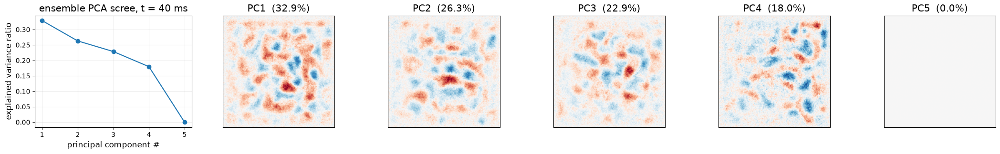

In [10]:
# Ensemble PCA at t = 40 ms: rotate each shot, crop to the inscribed square
# (no zero borders), then ONE PCA over all shots (each image = one sample).
# With n shots there are at most n-1 nonzero components.
T_PCA = 40


def rotate_and_crop(od, angle=45):
    """Rotate and crop to the inscribed square so no zero padding remains."""
    rot = rotate(od, angle, reshape=False)
    c0, c1 = rot.shape[0] // 2, rot.shape[1] // 2
    h = int(min(rot.shape) / (2 * np.sqrt(2)))
    return rot[c0 - h:c0 + h, c1 - h:c1 + h]


cropped = [rotate_and_crop(shot.od) for shot in by_time[T_PCA]]
shape = cropped[0].shape
X = np.array([im.ravel() for im in cropped])   # (n_shots, n_pixels)
print(f"{len(cropped)} shots at t = {T_PCA} ms, data matrix {X.shape}")

pca = PCA()
pca.fit(X)
var = pca.explained_variance_ratio_
print("explained variance ratios:", np.round(var, 4))

# scree plot + each principal component reshaped back into an image
n_pc = len(var)
fig, axes = plt.subplots(1, n_pc + 1, figsize=(3.6 * (n_pc + 1), 3.4))
axes[0].plot(np.arange(1, n_pc + 1), var, "o-", color="C0")
axes[0].set_xticks(np.arange(1, n_pc + 1))
axes[0].set_xlabel("principal component #")
axes[0].set_ylabel("explained variance ratio")
axes[0].set_title(f"ensemble PCA scree, t = {T_PCA} ms")
axes[0].grid(alpha=0.25)
for j, ax in enumerate(axes[1:]):
    comp = pca.components_[j].reshape(shape)
    lim = np.abs(comp).max()
    ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC{j + 1}  ({var[j]:.1%})")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()


In [ ]:
# Ensemble PCA on the t = 40 ms dataset (2026-07-27_40ms/): same procedure as
# above (rotate 45deg, crop the inscribed square, one PCA with each image as a
# sample), but scree plot and PC images as separate figures.
PCA_DIR = os.path.join(SCRIPT_DIR, "2026-07-27_40ms")
N_SHOTS = 20     # how many shots to build the PCA from
N_PC_SHOW = 12   # leading components to image

shots60 = [ShotFile(p, cam=CAM, crop_box=CROP_BOX)
           for p in sorted(glob.glob(os.path.join(PCA_DIR, "*bec_box2*.h5")))]
cropped60 = [rotate_and_crop(shot.od) for shot in shots60[:N_SHOTS]]
shape60 = cropped60[0].shape
X60 = np.array([im.ravel() for im in cropped60])   # (n_shots, n_pixels)
print(f"{len(cropped60)} shots, data matrix {X60.shape}")

pca60 = PCA()
pca60.fit(X60)
var60 = pca60.explained_variance_ratio_
print("top-10 explained variance ratios:", np.round(var60[:10], 4))

# figure 1: scree plot over all components
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(np.arange(1, len(var60) + 1), var60, "o-", ms=4, color="C0")
ax.set_yscale("log")
ax.set_xlabel("principal component #")
ax.set_ylabel("explained variance ratio")
ax.set_title(f"ensemble PCA scree, {len(cropped60)} shots at t = 40 ms")
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()

# figure 2: the leading principal components as images
ncols = 4
nrows = int(np.ceil(N_PC_SHOW / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.2 * nrows))
for j, ax in enumerate(axes.ravel()):
    if j >= N_PC_SHOW:
        ax.axis("off")
        continue
    comp = pca60.components_[j].reshape(shape60)
    lim = np.abs(comp).max()
    ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC{j + 1}  ({var60[j]:.1%})", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"leading principal components (ensemble over {len(cropped60)} shots)")
fig.tight_layout()
plt.show()


In [ ]:
# Average domain length at t = 40 ms, raw vs cleaned: project out the first
# two principal components from every shot, with the PCA built from the first
# 20 shots and again from all 60. L from the structure-factor first moment,
# averaged over all 60 shots.
N_REMOVE = 2


def domain_length(od):
    """Domain length (px) from the structure factor: L = 2 pi <S> / <k S>."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)
    return 2 * np.pi * S.sum() / (k_mag * S).sum()


def remove_leading_pcs(X, pca_fit, n_remove):
    """Project the leading n_remove components out of each row of X."""
    comps = pca_fit.components_[:n_remove]
    return X - (X - pca_fit.mean_) @ comps.T @ comps


cropped_all = [rotate_and_crop(shot.od) for shot in shots60]   # all 60 shots
X_all = np.array([im.ravel() for im in cropped_all])

results = {}
L_raw = np.array([domain_length(im) for im in cropped_all])
results["raw"] = L_raw
for n_fit in (20, 60):
    pca_fit = PCA().fit(X_all[:n_fit])
    X_clean = remove_leading_pcs(X_all, pca_fit, N_REMOVE)
    results[f"PCA {n_fit} shots"] = np.array(
        [domain_length(x.reshape(shape60)) for x in X_clean])

for label, Ls in results.items():
    sem = Ls.std(ddof=1) / np.sqrt(len(Ls))
    print(f"{label:>14}:  <L> = {Ls.mean():6.2f} +/- {sem:.2f} px   "
          f"(shot-to-shot std {Ls.std(ddof=1):.2f})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
labels = list(results)
means = [results[l].mean() for l in labels]
sems = [results[l].std(ddof=1) / np.sqrt(len(results[l])) for l in labels]
ax.errorbar(labels, means, yerr=sems, fmt="o", ms=7, capsize=4, color="C0")
ax.set_ylabel("mean domain size  L  (px)")
ax.set_title(f"t = 40 ms: <L> over 60 shots, first {N_REMOVE} PCs removed")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Sweep the number of removed PCs and watch when <L> starts to move:
# that's where the elimination stops cutting artifact and starts cutting
# the domain signal itself. Both PCA fits (20 and 60 shots), all 60 shots.
N_SWEEP = [0, 1, 2, 3, 5, 8, 10, 15, 19, 30, 45, 59]

fig, ax = plt.subplots(figsize=(8, 5))
for n_fit, color in ((20, "C0"), (60, "C1")):
    pca_fit = PCA().fit(X_all[:n_fit])
    n_max = n_fit - 1                     # nonzero components available
    ns = [n for n in N_SWEEP if n <= n_max]
    means, sems = [], []
    for n in ns:
        X_clean = remove_leading_pcs(X_all, pca_fit, n) if n else X_all
        Ls = np.array([domain_length(x.reshape(shape60)) for x in X_clean])
        means.append(Ls.mean())
        sems.append(Ls.std(ddof=1) / np.sqrt(len(Ls)))
        print(f"PCA {n_fit} shots, {n:2d} PCs removed:  "
              f"<L> = {Ls.mean():6.2f} +/- {sems[-1]:.2f} px")
    ax.errorbar(ns, means, yerr=sems, fmt="o-", ms=5, capsize=3,
                color=color, label=f"PCA from {n_fit} shots")
    print()
ax.set_xlabel("number of leading PCs removed")
ax.set_ylabel("mean domain size  L  (px)")
ax.set_title("t = 40 ms: <L> over 60 shots vs PCs removed")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Domain size vs evolution time over the WHOLE dataset (0-800 ms, ~5 shots
# per time): one ensemble PCA over all shots, remove the first principal
# component, then L = 2pi <S> / <k S> per cleaned shot on the rotated + cropped
# square, converted to microns (0.66 um/px). Linear graph here, log-log next cell.
PIXEL_UM = 0.66     # camera scale, microns per pixel
N_REMOVE_EVO = 1

t_shots, crops = [], []
for t in times:
    for shot in by_time[t]:
        t_shots.append(t)
        crops.append(rotate_and_crop(shot.od))
t_shots = np.array(t_shots, float)
shape_evo = crops[0].shape
X_evo = np.array([im.ravel() for im in crops])
print(f"{len(X_evo)} shots across {len(times)} times, matrix {X_evo.shape}")

pca_evo = PCA().fit(X_evo)
print("top-5 variance ratios:", np.round(pca_evo.explained_variance_ratio_[:5], 4))
X_evo_clean = remove_leading_pcs(X_evo, pca_evo, N_REMOVE_EVO)

L_shots = np.array([domain_length(x.reshape(shape_evo))
                    for x in X_evo_clean]) * PIXEL_UM
t_mean = np.array(times, float)
L_mean = np.array([L_shots[t_shots == t].mean() for t in times])
L_sem = np.array([L_shots[t_shots == t].std(ddof=1)
                  / np.sqrt((t_shots == t).sum()) for t in times])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(t_mean, L_mean, yerr=L_sem, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title(f"domain size vs evolution time (first {N_REMOVE_EVO} PC removed)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Same data on log-log axes: log10(L) vs log10(t) for t > 0, with the
# coarsening power law L = A t^(1/3) as the fit line -- slope fixed at 1/3,
# only the amplitude A fitted (least squares in log space).
pos_s = t_shots > 0
pos_m = t_mean > 0
logt_m, logL_m = np.log10(t_mean[pos_m]), np.log10(L_mean[pos_m])
logA = (logL_m - logt_m / 3).mean()          # best-fit amplitude at fixed slope

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.log10(t_shots[pos_s]), np.log10(L_shots[pos_s]), "o", ms=3,
        color="C0", alpha=0.3, label="individual shots")
ax.plot(logt_m, logL_m, "o", ms=6, color="C0", label="mean of repeats")
ax.plot(logt_m, logt_m / 3 + logA, "k--", alpha=0.6,
        label=rf"$L = {10**logA:.2f}\,t^{{1/3}}$  (coarsening law)")
ax.set_xlabel(r"$\log_{10}\, t$  (t in ms)")
ax.set_ylabel(r"$\log_{10}\, L$  (L in $\mu$m)")
ax.set_title(f"log-log domain growth (first {N_REMOVE_EVO} PC removed)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print(f"t^(1/3) coarsening law, fitted amplitude: "
      f"L = {10**logA:.2f} um * t^(1/3)  (t in ms)")


In [ ]:
# Same domain-size-vs-time graph with NO principal components removed
# (raw rotated + cropped shots, reusing X_evo / t_shots from the PCA cell).
L_shots_raw = np.array([domain_length(x.reshape(shape_evo))
                        for x in X_evo]) * PIXEL_UM
L_mean_raw = np.array([L_shots_raw[t_shots == t].mean() for t in times])
L_sem_raw = np.array([L_shots_raw[t_shots == t].std(ddof=1)
                      / np.sqrt((t_shots == t).sum()) for t in times])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots_raw, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(t_mean, L_mean_raw, yerr=L_sem_raw, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("domain size vs evolution time (no PCs removed)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Same graph with the first TWO principal components removed
# (same ensemble PCA pca_evo, just a deeper cut).
X_evo_clean2 = remove_leading_pcs(X_evo, pca_evo, 2)
L_shots_2 = np.array([domain_length(x.reshape(shape_evo))
                      for x in X_evo_clean2]) * PIXEL_UM
L_mean_2 = np.array([L_shots_2[t_shots == t].mean() for t in times])
L_sem_2 = np.array([L_shots_2[t_shots == t].std(ddof=1)
                    / np.sqrt((t_shots == t).sum()) for t in times])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots_2, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(t_mean, L_mean_2, yerr=L_sem_2, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("domain size vs evolution time (first 2 PCs removed)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Tukey window INSTEAD of rotate+crop: take the raw OD, subtract its mean and
# taper with the 2D tukey window (kills the edge discontinuity the FFT sees),
# then the same L = 2pi <S> / <k S>. No PCA cleaning.
WIN_ALPHA = 0.5   # tukey taper fraction (0 = no taper, 1 = full hann-like)


def domain_length_windowed(od, alpha=WIN_ALPHA):
    fluct = (od - od.mean()) * _tukey2d(od.shape, alpha)
    return domain_length(fluct)


L_shots_win = np.array([domain_length_windowed(shot.od)
                        for t in times for shot in by_time[t]]) * PIXEL_UM
L_mean_win = np.array([L_shots_win[t_shots == t].mean() for t in times])
L_sem_win = np.array([L_shots_win[t_shots == t].std(ddof=1)
                      / np.sqrt((t_shots == t).sum()) for t in times])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots_win, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(t_mean, L_mean_win, yerr=L_sem_win, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title(f"domain size vs evolution time "
             f"(tukey window alpha = {WIN_ALPHA}, no crop, no PCA)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [ ]:
# Gallery of cleaned shots (first PC removed) across the evolution, 20 times
# with nonlinear spacing: 10 ms steps to 50, the finer experimental steps to
# 200, then 100 ms steps to 800. One shot (first repeat) per time.
SNAP_TIMES = [0, 10, 20, 30, 40, 50,
              62, 75, 88, 100, 125, 150, 175, 200,
              300, 400, 500, 600, 700, 800]

fig, axes = plt.subplots(4, 5, figsize=(16, 13))
for ax, t in zip(axes.ravel(), SNAP_TIMES):
    idx = np.flatnonzero(t_shots == t)[0]          # first repeat at this time
    im = X_evo_clean[idx].reshape(shape_evo)
    ax.imshow(im)
    ax.set_title(f"t = {t} ms", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("cleaned shots (first PC removed), rotated + cropped OD")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


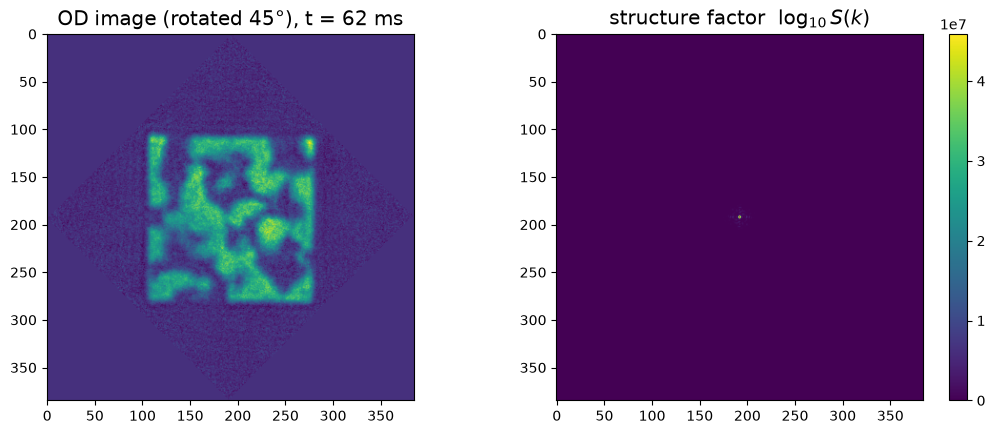

In [ ]:
# Debug view: rotated OD next to its structure factor
from scipy.ndimage import rotate

od_rotated = rotate(sf.od, 45, reshape=True, order=1)
S = np.fft.fftshift(domain_size(od_rotated))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(od_rotated)
axes[0].set_title(f"OD image (rotated 45°), t = {t} ms")
im = axes[1].imshow(S)#np.log10(S + S[S > 0].min()))
axes[1].set_title(r"S(k)$")
fig.colorbar(im, ax=axes[1])
fig.tight_layout()
plt.show()


 t (ms)   L (px)
      0    30.73
      0    32.08
      0    31.33
      0    29.19
      0    28.21
     10    25.38
     10    30.56
     10    28.64
     10    28.84
     10    24.47
     20    26.78
     20    20.66
     20    26.77
     20    25.87
     20    24.02
     30    23.75
     30    27.92
     30    27.44
     30    27.67
     30    26.10
     40    28.24
     40    27.82
     40    24.31
     40    25.76
     40    25.36
     50    28.28
     50    27.66
     50    28.28
     50    32.83
     50    31.23
     62    27.94
     62    24.90
     62    26.69
     62    27.71
     62    23.56
     75    23.96
     75    26.12
     75    28.90
     75    24.90
     75    22.11
     88    29.83
     88    26.10
     88    26.43
     88    29.63
     88    26.30
    100    31.21
    100    30.80
    100    31.32
    100    33.30
    100    31.00
    125    30.92
    125    27.41
    125    27.26
    125    28.19
    125    29.68
    150    33.64
    150    28.02
    150    32.

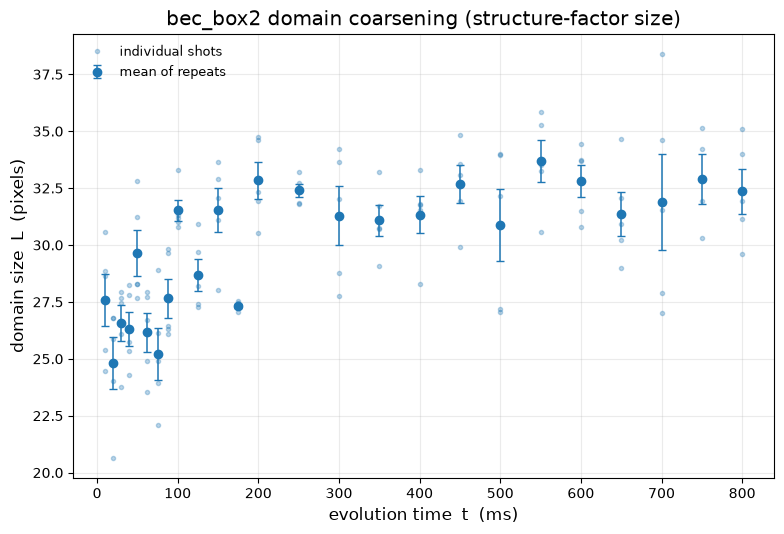

In [97]:
# Domain size L for EVERY shot: L = 2 pi <S> / <k S>, printed and plotted.
def domain_length(od):
    """Scalar domain length (pixels) from the structure factor returned by domain_size."""
    S = domain_size(od)
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)
    return 2 * np.pi * S.sum() / (k_mag * S).sum()

all_t, all_L = [], []                    # every individual shot
mean_t, mean_L, sem_L = [], [], []
print(f"{'t (ms)':>7}  {'L (px)':>7}")
for t in times:
    Ls = np.array([domain_length(sf.od) for sf in by_time[t]])
    for L in Ls:                         # print all the points
        print(f"{t:7d}  {L:7.2f}")
    all_t.extend([t] * len(Ls))
    all_L.extend(Ls)
    mean_t.append(t)
    mean_L.append(Ls.mean())
    sem_L.append(Ls.std(ddof=1) / np.sqrt(len(Ls)) if len(Ls) > 1 else 0.0)

all_t = np.array(all_t, float)
all_L = np.array(all_L, float)
mean_t = np.array(mean_t, float)
mean_L = np.array(mean_L, float)
sem_L = np.array(sem_L, float)

# L = A t^(1/3) fit over the growth window
fit_mask = (mean_t >= FIT_MIN_MS) & (mean_t <= FIT_MAX_MS)
(A,), _ = curve_fit(cube_root, mean_t[fit_mask], mean_L[fit_mask], p0=(4.0,))
resid = mean_L[fit_mask] - cube_root(mean_t[fit_mask], A)
r2 = 1 - np.sum(resid**2) / np.sum((mean_L[fit_mask] - mean_L[fit_mask].mean())**2)
print(f"\ncube-root fit over {FIT_MIN_MS}-{FIT_MAX_MS} ms: "
      f"L(t) = {A:.3f} * t^(1/3)  R^2 = {r2:.3f}")

# log-log plot: every shot as a faint point, means with error bars, fit line
pos = all_t > 0
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(all_t[pos], all_L[pos], "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(mean_t[mean_t > 0], mean_L[mean_t > 0], yerr=sem_L[mean_t > 0],
            fmt="o", ms=6, color="C0", capsize=3, lw=1.1,
            label="mean of repeats", zorder=3)
tt = np.linspace(mean_t[mean_t > 0].min(), mean_t.max(), 400)
# ax.plot(tt, cube_root(tt, 4), "--", color="0.25", lw=1.8,
#         label=rf"$L = {1:.1f}\,t^{{1/3}}$  ($R^2$={r2:.2f})", zorder=4)
# ax.set_xscale("log")
# ax.set_yscale("log")
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel("domain size  L  (pixels)")
ax.set_title("bec_box2 domain coarsening (structure-factor size)")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()


In [ ]:
#!/Users/nolexnol/quantum_sim/venv/bin/python
"""
Average coarsening (domain) size vs. evolution time for the bec_box2 dataset.

For every shot we measure a characteristic domain length (in pixels) from the
first moment of the spin structure factor -- the same estimator used for the
simulation in run_binary_coarsening.py:

    L = 2 pi <S> / <k S>,     S(k) = |FFT2(fluctuation field)|^2,  S(0) = 0

Idea: the structure factor S(k) is the power spectrum of the density-contrast
field; it tells you how much of the pattern lives at each spatial wavenumber k
(k ~ 1/length). Big domains -> power piled up at small k; fine structure ->
power at large k. The ratio <S>/<k S> is the S-weighted mean of 1/k, i.e. a
characteristic length, and the 2 pi turns it into a real-space size. As domains
coarsen, spectral weight shifts to small k and L grows.

Because the experimental cloud has a smooth envelope that would dominate the
low-k power, we first high-pass each image (subtract a broad Gaussian blur) and
apodize with a 2D Hann window before the FFT. L comes out in pixels.

The figure is a log-log plot (like results/bin_course_growth_old.png): every
individual shot as a faint point, the per-time mean of the ~5 repeats as a solid
marker, and a curvature-driven L = A t^(1/3) coarsening fit drawn as the
reference power law.
"""
import os
import re
import glob
import sys

import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
from quantum_sim.io import ShotFile

DATA_DIR = os.path.join(os.path.dirname(__file__), "coarsening_data")
RESULTS_DIR = os.path.join(os.path.dirname(__file__), "..", "results")

CAM = "cam6"
TIME_INDEX = 6                      # swept element of BEC_TIME_SEQ (seconds)
CROP_BOX = [130, 400, 105, 380]     # rows[0:1], cols[2:3] around the cloud
BG_SIGMA = 20.0                     # px; blur scale removed to kill the envelope
FIT_MIN_MS = 10                     # window used to anchor the t^(1/3) amplitude
FIT_MAX_MS = 100                    # (the domain-growth regime before saturation)

NAME_RE = re.compile(
    r"^(?P<seq>\d{4}-\d{2}-\d{2}_\d{4})_bec_box2_(?P<idx>\d+)"
    r"(?:_rep(?P<rep>\d+))?\.h5$"
)


def collect_shots():
    """Map evolution_time_ms -> list of ShotFile over every bec_box2 shot."""
    by_time = {}
    for path in glob.glob(os.path.join(DATA_DIR, "*bec_box2*.h5")):
        if not NAME_RE.match(os.path.basename(path)):
            continue
        sf = ShotFile(path, cam=CAM, crop_box=CROP_BOX)
        t_ms = round(float(np.asarray(sf.BEC_TIME_SEQ)[TIME_INDEX]) * 1e3)
        by_time.setdefault(t_ms, []).append(sf)
    return by_time


def _hann2d(shape):
    wy = np.hanning(shape[0])
    wx = np.hanning(shape[1])
    return np.outer(wy, wx)


def domain_size(od):
    """Characteristic domain length (pixels) from the structure-factor 1st moment.

    High-pass to drop the cloud envelope, apodize, then L = 2 pi <S> / <k S>.
    """
    fluct = od #- gaussian_filter(od, sigma=BG_SIGMA)
    # fluct = (fluct - fluct.mean()) #* _hann2d(od.shape)

    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)          # rad / pixel
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)

    S = np.abs(np.fft.fft2(fluct))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    return S


def cube_root(t, A):
    """Curvature-driven coarsening law L = A t^(1/3)."""
    return A * np.cbrt(t)


def main():
    os.makedirs(RESULTS_DIR, exist_ok=True)
    by_time = collect_shots()
    times = sorted(by_time)
    print(f"{sum(len(v) for v in by_time.values())} shots across "
          f"{len(times)} evolution times: {times[0]}..{times[-1]} ms")

    # per-shot domain size, grouped by evolution time
    all_t, all_L = [], []          # every individual shot
    mean_t, mean_L, sem_L = [], [], []
    for t in times:
        sizes = np.array([np.fft.fftshift(domain_size(sf.od)) for sf in by_time[t]])
        all_t.extend([t] * len(sizes))
        all_L.extend(sizes)
        mean_t.append(t)
        mean_L.append(sizes.mean())
        sem_L.append(sizes.std(ddof=1) / np.sqrt(len(sizes)) if len(sizes) > 1 else 0.0)
        print(f"  t = {t:4d} ms  n = {len(sizes)}  "
              f"L = {sizes.mean():5.2f} +/- {sem_L[-1]:.2f} px")

    all_t = np.array(all_t, float)
    # all_L = np.array(all_L, float)
    mean_t = np.array(mean_t, float)
    mean_L = np.array(mean_L, float)
    sem_L = np.array(sem_L, float)

    # L = A t^(1/3): fit the amplitude over the growth window (before saturation)
    fit_mask = (mean_t >= FIT_MIN_MS) & (mean_t <= FIT_MAX_MS)
    (A,), _ = curve_fit(cube_root, mean_t[fit_mask], mean_L[fit_mask], p0=(4.0,))
    resid = mean_L[fit_mask] - cube_root(mean_t[fit_mask], A)
    r2 = 1 - np.sum(resid**2) / np.sum((mean_L[fit_mask] - mean_L[fit_mask].mean())**2)
    print(f"\ncube-root fit over {FIT_MIN_MS}-{FIT_MAX_MS} ms:")
    print(f"  L(t) = {A:.3f} * t^(1/3)  (px, t in ms)   R^2 = {r2:.3f}")

    # log-log figure
    pos = all_t > 0
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.imshow(all_L[6])
    # ax.errorbar(mean_t[mean_t > 0], mean_L[mean_t > 0], yerr=sem_L[mean_t > 0],
    #             fmt="o", ms=6, color="C0", capsize=3, lw=1.1,
    #             label="mean of repeats", zorder=3)

    tt = np.linspace(mean_t[mean_t > 0].min(), mean_t.max(), 400)
    # ax.plot(tt, cube_root(tt, A), "--", color="0.25", lw=1.8,
    #         label=rf"$L = {A:.1f}\,t^{{1/3}}$   ($R^2$={r2:.2f} over "
    #               rf"{FIT_MIN_MS}-{FIT_MAX_MS} ms)", zorder=4)

    # ax.set_xscale("log")
    # ax.set_yscale("log")
    ax.set_xlabel("evolution time  t  (ms)")
    ax.set_ylabel("domain size  L  (pixels)")
    ax.set_title("bec_box2 domain coarsening (structure-factor size)")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.25, which="both")
    fig.tight_layout()

    out = os.path.join(RESULTS_DIR, "coarsening_size.png")
    fig.savefig(out, dpi=140)
    plt.close(fig)
    print(f"Saved {os.path.abspath(out)}")


if __name__ == "__main__":
    main()


NameError: name '__file__' is not defined

In [ ]:
#!/Users/nolexnol/quantum_sim/venv/bin/python
"""
Average coarsening (domain) size vs. evolution time for the bec_box2 dataset.

For every shot we measure a characteristic domain length (in pixels) from the
first moment of the spin structure factor -- the same estimator used for the
simulation in run_binary_coarsening.py:

    L = 2 pi <S> / <k S>,     S(k) = |FFT2(fluctuation field)|^2,  S(0) = 0

Idea: the structure factor S(k) is the power spectrum of the density-contrast
field; it tells you how much of the pattern lives at each spatial wavenumber k
(k ~ 1/length). Big domains -> power piled up at small k; fine structure ->
power at large k. The ratio <S>/<k S> is the S-weighted mean of 1/k, i.e. a
characteristic length, and the 2 pi turns it into a real-space size. As domains
coarsen, spectral weight shifts to small k and L grows.

Because the experimental cloud has a smooth envelope that would dominate the
low-k power, we first high-pass each image (subtract a broad Gaussian blur) and
apodize with a 2D Hann window before the FFT. L comes out in pixels.

The figure is a log-log plot (like results/bin_course_growth_old.png): every
individual shot as a faint point, the per-time mean of the ~5 repeats as a solid
marker, and a curvature-driven L = A t^(1/3) coarsening fit drawn as the
reference power law.
"""
import os
import re
import glob
import sys

import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
from quantum_sim.io import ShotFile

DATA_DIR = os.path.join(os.path.dirname(__file__), "coarsening_data")
RESULTS_DIR = os.path.join(os.path.dirname(__file__), "..", "results")

CAM = "cam6"
TIME_INDEX = 6                      # swept element of BEC_TIME_SEQ (seconds)
CROP_BOX = [130, 400, 105, 380]     # rows[0:1], cols[2:3] around the cloud
BG_SIGMA = 20.0                     # px; blur scale removed to kill the envelope
FIT_MIN_MS = 10                     # window used to anchor the t^(1/3) amplitude
FIT_MAX_MS = 100                    # (the domain-growth regime before saturation)

NAME_RE = re.compile(
    r"^(?P<seq>\d{4}-\d{2}-\d{2}_\d{4})_bec_box2_(?P<idx>\d+)"
    r"(?:_rep(?P<rep>\d+))?\.h5$"
)


def collect_shots():
    """Map evolution_time_ms -> list of ShotFile over every bec_box2 shot."""
    by_time = {}
    for path in glob.glob(os.path.join(DATA_DIR, "*bec_box2*.h5")):
        if not NAME_RE.match(os.path.basename(path)):
            continue
        sf = ShotFile(path, cam=CAM, crop_box=CROP_BOX)
        t_ms = round(float(np.asarray(sf.BEC_TIME_SEQ)[TIME_INDEX]) * 1e3)
        by_time.setdefault(t_ms, []).append(sf)
    return by_time


def _hann2d(shape):
    wy = np.hanning(shape[0])
    wx = np.hanning(shape[1])
    return np.outer(wy, wx)


def domain_size(od):
    """Characteristic domain length (pixels) from the structure-factor 1st moment.

    High-pass to drop the cloud envelope, apodize, then L = 2 pi <S> / <k S>.
    """
    fluct = od #- gaussian_filter(od, sigma=BG_SIGMA)
    # fluct = (fluct - fluct.mean()) #* _hann2d(od.shape)

    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)          # rad / pixel
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)

    S = np.abs(np.fft.fft2(fluct))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    return S


def cube_root(t, A):
    """Curvature-driven coarsening law L = A t^(1/3)."""
    return A * np.cbrt(t)


def main():
    os.makedirs(RESULTS_DIR, exist_ok=True)
    by_time = collect_shots()
    times = sorted(by_time)
    print(f"{sum(len(v) for v in by_time.values())} shots across "
          f"{len(times)} evolution times: {times[0]}..{times[-1]} ms")

    # per-shot domain size, grouped by evolution time
    all_t, all_L = [], []          # every individual shot
    mean_t, mean_L, sem_L = [], [], []
    for t in times:
        sizes = np.array([np.fft.fftshift(domain_size(sf.od)) for sf in by_time[t]])
        all_t.extend([t] * len(sizes))
        all_L.extend(sizes)
        mean_t.append(t)
        mean_L.append(sizes.mean())
        sem_L.append(sizes.std(ddof=1) / np.sqrt(len(sizes)) if len(sizes) > 1 else 0.0)
        print(f"  t = {t:4d} ms  n = {len(sizes)}  "
              f"L = {sizes.mean():5.2f} +/- {sem_L[-1]:.2f} px")

    all_t = np.array(all_t, float)
    # all_L = np.array(all_L, float)
    mean_t = np.array(mean_t, float)
    mean_L = np.array(mean_L, float)
    sem_L = np.array(sem_L, float)

    # L = A t^(1/3): fit the amplitude over the growth window (before saturation)
    fit_mask = (mean_t >= FIT_MIN_MS) & (mean_t <= FIT_MAX_MS)
    (A,), _ = curve_fit(cube_root, mean_t[fit_mask], mean_L[fit_mask], p0=(4.0,))
    resid = mean_L[fit_mask] - cube_root(mean_t[fit_mask], A)
    r2 = 1 - np.sum(resid**2) / np.sum((mean_L[fit_mask] - mean_L[fit_mask].mean())**2)
    print(f"\ncube-root fit over {FIT_MIN_MS}-{FIT_MAX_MS} ms:")
    print(f"  L(t) = {A:.3f} * t^(1/3)  (px, t in ms)   R^2 = {r2:.3f}")

    # log-log figure
    pos = all_t > 0
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.imshow(all_L[6])
    # ax.errorbar(mean_t[mean_t > 0], mean_L[mean_t > 0], yerr=sem_L[mean_t > 0],
    #             fmt="o", ms=6, color="C0", capsize=3, lw=1.1,
    #             label="mean of repeats", zorder=3)

    tt = np.linspace(mean_t[mean_t > 0].min(), mean_t.max(), 400)
    # ax.plot(tt, cube_root(tt, A), "--", color="0.25", lw=1.8,
    #         label=rf"$L = {A:.1f}\,t^{{1/3}}$   ($R^2$={r2:.2f} over "
    #               rf"{FIT_MIN_MS}-{FIT_MAX_MS} ms)", zorder=4)

    # ax.set_xscale("log")
    # ax.set_yscale("log")
    ax.set_xlabel("evolution time  t  (ms)")
    ax.set_ylabel("domain size  L  (pixels)")
    ax.set_title("bec_box2 domain coarsening (structure-factor size)")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.25, which="both")
    fig.tight_layout()

    out = os.path.join(RESULTS_DIR, "coarsening_size.png")
    fig.savefig(out, dpi=140)
    plt.close(fig)
    print(f"Saved {os.path.abspath(out)}")


if __name__ == "__main__":
    main()


NameError: name '__file__' is not defined

In [72]:
# Analysis stages on one example shot: raw OD -> gaussian bg removed -> windowed -> PSD^0.25
# (each stage plotted in its own cell below)
PSD_BG_SIGMA = 10.0   # px; high-pass scale (features larger than this are removed)
PSD_ALPHA = 0.2       # tukey taper fraction; 0 = no window


def shot_psd(od, bg_sigma=PSD_BG_SIGMA, alpha=PSD_ALPHA):
    """PSD of the windowed density fluctuations, fftshifted so k=0 is centered."""
    bg = gaussian_filter(od, sigma=bg_sigma) if bg_sigma else 0.0
    fluct = od - bg
    fluct = (fluct - fluct.mean()) * _tukey2d(od.shape, alpha)
    S = np.abs(np.fft.fft2(fluct))**2
    S[0, 0] = 0.0
    return np.fft.fftshift(S)


# k axes in rad/pixel, shared by every shot (same crop -> same shape)
ky = np.fft.fftshift(2 * np.pi * np.fft.fftfreq(sf.od.shape[0]))
kx = np.fft.fftshift(2 * np.pi * np.fft.fftfreq(sf.od.shape[1]))

od = sf.od
bg = gaussian_filter(od, sigma=PSD_BG_SIGMA)
fluct = od - bg
windowed = (fluct - fluct.mean()) * _tukey2d(od.shape, PSD_ALPHA)
S = shot_psd(od)


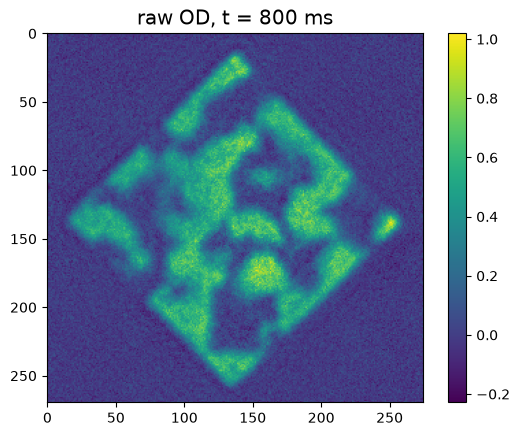

In [73]:
# Stage 1: raw OD
plt.imshow(od)
plt.title(f"raw OD, t = {t} ms")
plt.colorbar()
plt.show()


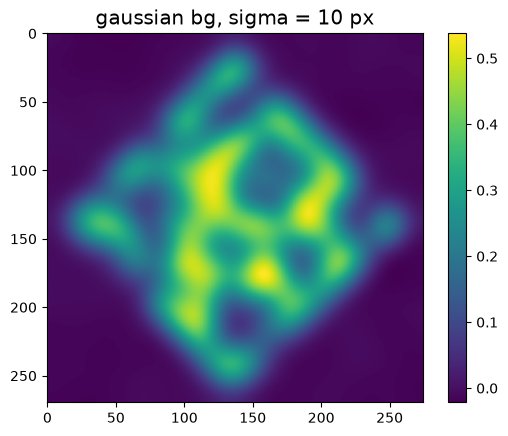

In [74]:
# Stage 2: the gaussian background (the smooth envelope we remove)
plt.imshow(bg)
plt.title(f"gaussian bg, sigma = {PSD_BG_SIGMA:.0f} px")
plt.colorbar()
plt.show()


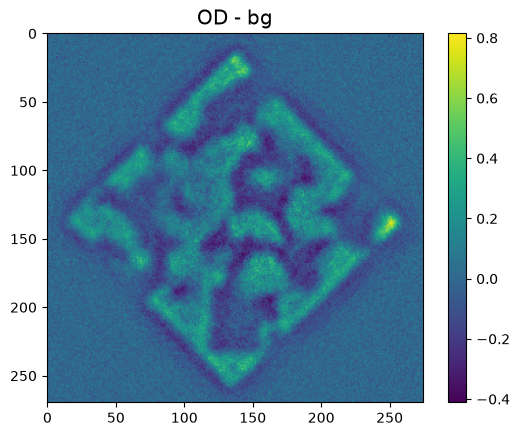

In [75]:
# Stage 3: fluctuation field, OD - bg
plt.imshow(fluct)
plt.title("OD - bg")
plt.colorbar()
plt.show()


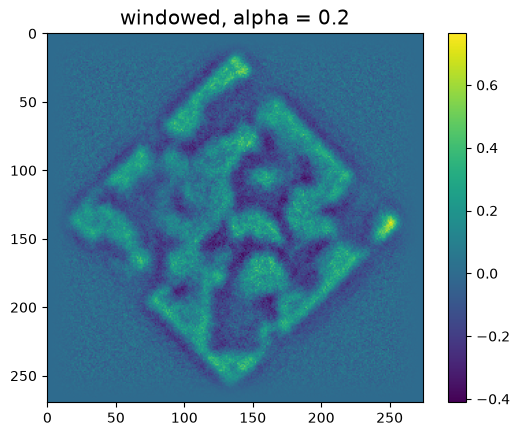

In [76]:
# Stage 4: mean-subtracted and tukey-windowed (kills the hard crop edges)
plt.imshow(windowed)
plt.title(f"windowed, alpha = {PSD_ALPHA}")
plt.colorbar()
plt.show()


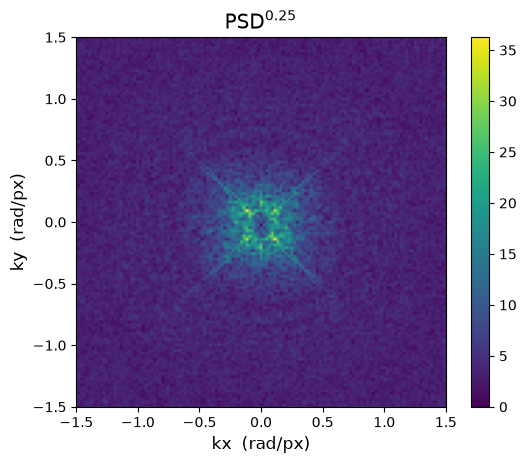

In [77]:
# Stage 5: PSD^0.25, zoomed to low k
plt.imshow(S**0.25, extent=[kx.min(), kx.max(), ky.min(), ky.max()])
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.xlabel("kx  (rad/px)")
plt.ylabel("ky  (rad/px)")
plt.title(r"PSD$^{0.25}$")
plt.colorbar()
plt.show()


KeyError: 550

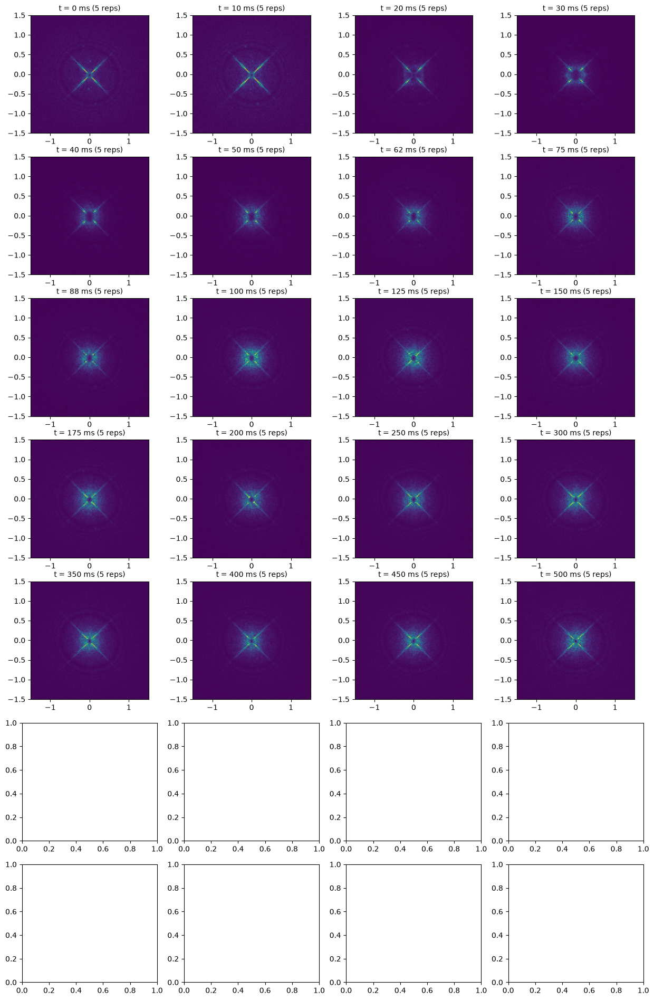

In [85]:
# Repeat-averaged 2D PSD at each hold time, plotted as PSD^0.25 to bring up the small signal.
# A coarsening peak should be a RING (domains are isotropic); isolated bright spots
# are fringes, and a bright cross through k=0 is the crop edges / cloud envelope.
mean_psd = {}
for t in times[:20]:
    mean_psd[t] = np.mean([shot_psd(sf.od) for sf in by_time[t]], axis=0)

KLIM = 1.5   # rad/px; zoom on the low-k region where the domain signal lives

ncols = 4
nrows = int(np.ceil(len(times) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 3.4 * nrows))
for ax, t in zip(axes.ravel(), times):
    im = ax.imshow(mean_psd[t]**0.5, extent=[kx.min(), kx.max(), ky.min(), ky.max()])
    ax.set_xlim(-KLIM, KLIM)
    ax.set_ylim(-KLIM, KLIM)
    ax.set_title(f"t = {t} ms ({len(by_time[t])} reps)", fontsize=10)
for ax in axes.ravel()[len(times):]:
    ax.axis("off")
fig.suptitle(r"repeat-averaged PSD$^{0.25}$")
fig.tight_layout()
plt.show()


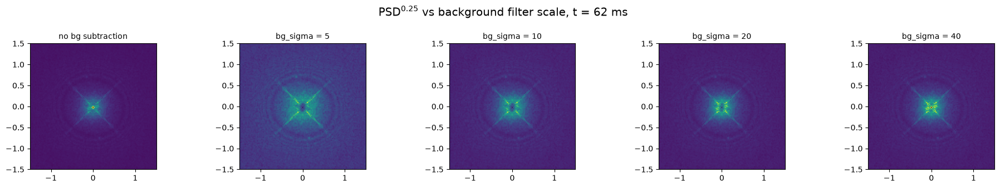

In [79]:
# Is the background filter erasing the signal?  Same hold time, different bg_sigma.
# The high-pass kills structure at k below roughly 1/sigma, so if the ring sits at
# k_peak we need sigma well above 1/k_peak (i.e. sigma >> L/2pi).  0 = no subtraction.
SIGMAS = [0, 5, 10, 20, 40]

t_show = times[6] if len(times) > 6 else times[-1]
fig, axes = plt.subplots(1, len(SIGMAS), figsize=(3.8 * len(SIGMAS), 3.4))
for ax, sig in zip(axes, SIGMAS):
    S_mean = np.mean([shot_psd(sf.od, bg_sigma=sig) for sf in by_time[t_show]], axis=0)
    ax.imshow(S_mean**0.25, extent=[kx.min(), kx.max(), ky.min(), ky.max()])
    ax.set_xlim(-KLIM, KLIM)
    ax.set_ylim(-KLIM, KLIM)
    ax.set_title(f"bg_sigma = {sig}" if sig else "no bg subtraction", fontsize=10)
fig.suptitle(rf"PSD$^{{0.25}}$ vs background filter scale, t = {t_show} ms")
fig.tight_layout()
plt.show()


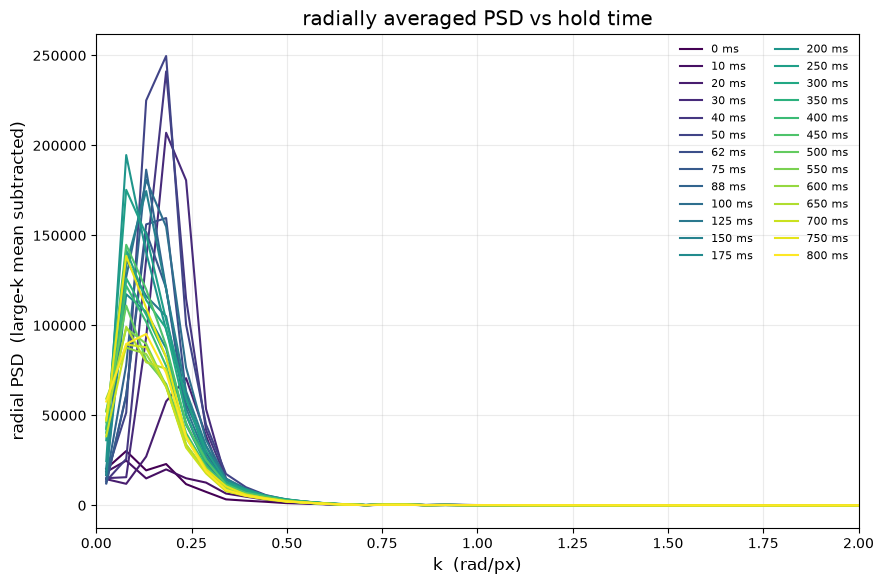

In [ ]:
    # Reduce 2D -> 1D: average the PSD over rings of constant |k|,
# then plot every hold time on the same axes with the large-k floor subtracted.
N_BINS = 60
K_HIGH = 2.0   # rad/px; above this we assume flat noise, use its mean as the floor


def radial_average(S, n_bins=N_BINS):
    KX, KY = np.meshgrid(kx, ky)
    k = np.sqrt(KX**2 + KY**2).ravel()
    bins = np.linspace(0, np.pi, n_bins + 1)   # out to the axis Nyquist k
    which = np.digitize(k, bins) - 1
    s = S.ravel()
    prof = np.array([s[which == i].mean() for i in range(n_bins)])
    k_mid = 0.5 * (bins[:-1] + bins[1:])
    return k_mid, prof


profiles = {}
fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(times)))
for t, c in zip(times, colors):
    k_mid, prof = radial_average(mean_psd[t])
    prof = prof - prof[k_mid > K_HIGH].mean()   # subtract the large-k mean
    profiles[t] = (k_mid, prof)
    ax.plot(k_mid, prof, color=c, label=f"{t} ms")
ax.set_xlim(0, K_HIGH)
ax.set_xlabel("k  (rad/px)")
ax.set_ylabel("radial PSD  (large-k mean subtracted)")
ax.set_title("radially averaged PSD vs hold time")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


 t (ms)   k_peak   L (px)
      0    0.131    48.00
     10    0.131    48.00
     20    0.236    26.67
     30    0.183    34.29
     40    0.183    34.29
     50    0.183    34.29
     62    0.131    48.00
     75    0.131    48.00
     88    0.131    48.00
    100    0.131    48.00
    125    0.131    48.00
    150    0.131    48.00
    175    0.131    48.00
    200    0.131    48.00
    250    0.131    48.00
    300    0.131    48.00
    350    0.131    48.00
    400    0.131    48.00
    450    0.131    48.00
    500    0.131    48.00
    550    0.131    48.00
    600    0.131    48.00
    650    0.131    48.00
    700    0.131    48.00
    750    0.131    48.00
    800    0.131    48.00


/var/folders/t5/0d8d10nd7_d8js2n4m1ynyrh0000gn/T/ipykernel_11785/4104891405.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


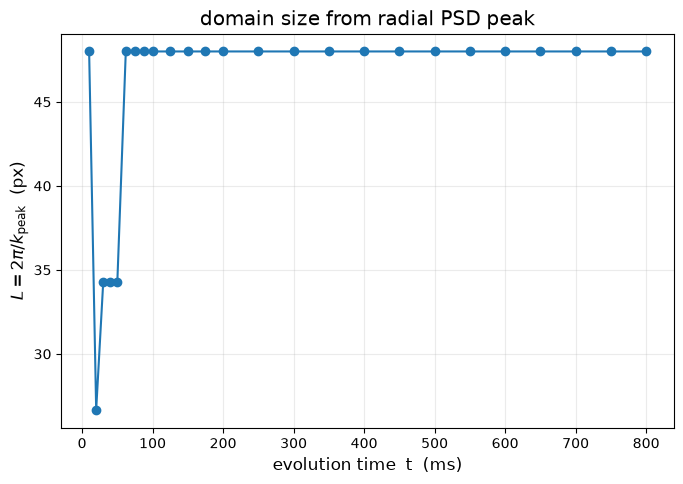

In [ ]:
# Find the peak of each radial profile -> k_peak(t) -> L = 2*pi/k_peak.
from scipy.ndimage import gaussian_filter1d

K_MIN = 0.08     # rad/px; skip the lowest bins (leftover envelope / window)
SMOOTH_BINS = 2  # light smoothing before the argmax

k_peaks = []
for t in times:
    k_mid, prof = profiles[t]
    smooth = gaussian_filter1d(prof, SMOOTH_BINS)
    sel = (k_mid > K_MIN) & (k_mid < K_HIGH)
    k_peaks.append(k_mid[sel][np.argmax(smooth[sel])])
k_peaks = np.array(k_peaks)
L_peak = 2 * np.pi / k_peaks

print(f"{'t (ms)':>7}  {'k_peak':>7}  {'L (px)':>7}")
for t, kp, L in zip(times, k_peaks, L_peak):
    print(f"{t:7d}  {kp:7.3f}  {L:7.2f}")

t_arr = np.array(times, float)
pos = t_arr > 0
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(t_arr[pos], L_peak[pos], "o-", color="C0")
tt = np.linspace(t_arr[pos].min(), t_arr[pos].max(), 200)
ax.plot(tt, L_peak[pos][0] * np.cbrt(tt / t_arr[pos][0]), "--", color="0.5",
        label=r"$t^{1/3}$ guide")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"$L = 2\pi / k_{\rm peak}$  (px)")
ax.set_title("domain size from radial PSD peak")
ax.legend(frameon=False)
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()


In [ ]:
# PCA via plain SVD, each shot = one sample. Unlike sklearn's PCA this does
# NOT subtract the mean first, so the leading component IS the shared
# envelope/box profile -- removing it cleans the static structure from every
# shot, and PC2+ capture shot-to-shot artifacts.
# Self-contained: builds its own image stack from by_time (only needs cell 0
# for collect_shots/by_time and the rotate_and_crop definition).
def pca_svd(images):
    """Return normalized S^2 and spatial PCA vectors for images [shot, x, y]."""
    images = np.asarray(images, dtype=float)
    if images.ndim != 3:
        raise ValueError("images must have shape [shot, x, y]")
    pixels_by_shot = images.reshape(images.shape[0], -1).T
    vectors, singular_values, _ = np.linalg.svd(pixels_by_shot, full_matrices=False)
    eigenvalues = singular_values**2
    total = eigenvalues.sum()
    if total == 0:
        raise ValueError("images must have non-zero variance")
    eigenvalues /= total
    return eigenvalues, vectors.reshape(*images.shape[1:], -1)


def remove_pca_components(image, eigenvectors, n_components):
    """Return (cleaned, removed) after projecting image onto leading components."""
    image = np.asarray(image, dtype=float)
    eigenvectors = np.asarray(eigenvectors, dtype=float)
    if image.ndim != 2 or eigenvectors.shape[:2] != image.shape:
        raise ValueError("image and eigenvectors have incompatible shapes")
    if not 0 <= n_components <= eigenvectors.shape[-1]:
        raise ValueError("n_components is outside the available basis")
    basis = eigenvectors[..., :n_components].reshape(image.size, n_components)
    removed = (basis @ (basis.T @ image.ravel())).reshape(image.shape)
    return image - removed, removed


def _domain_length_raw(od):
    """L = 2 pi <S> / <k S> in px, only the uniform mode dropped."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    return 2 * np.pi * S.sum() / (np.sqrt(KX**2 + KY**2) * S).sum()


PIXEL_UM_SVD = 0.66
WIN_ALPHA_SVD = 0.5
times_svd = sorted(by_time)
t_shots_svd, _stack = [], []
for _t in times_svd:
    for _sf in by_time[_t]:
        t_shots_svd.append(float(_t))
        _stack.append(rotate_and_crop(_sf.od))
t_shots_svd = np.array(t_shots_svd)
stack_svd = np.stack(_stack)              # [shot, x, y]
print(f"image stack: {stack_svd.shape}")

evr_svd, pcs_svd = pca_svd(stack_svd)
print("top-5 explained variance ratios:", np.round(evr_svd[:5], 4))


image stack: (129, 190, 190)
top-5 variance fractions: [0.7277 0.0328 0.0165 0.0135 0.0121]


image stack: (60, 270, 275)


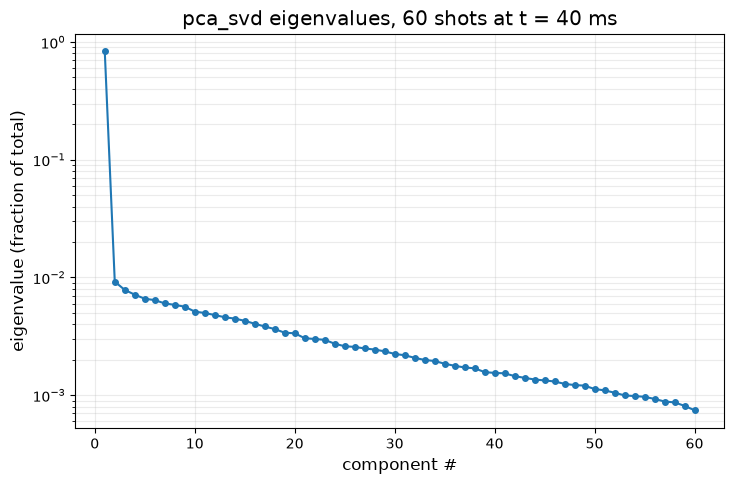

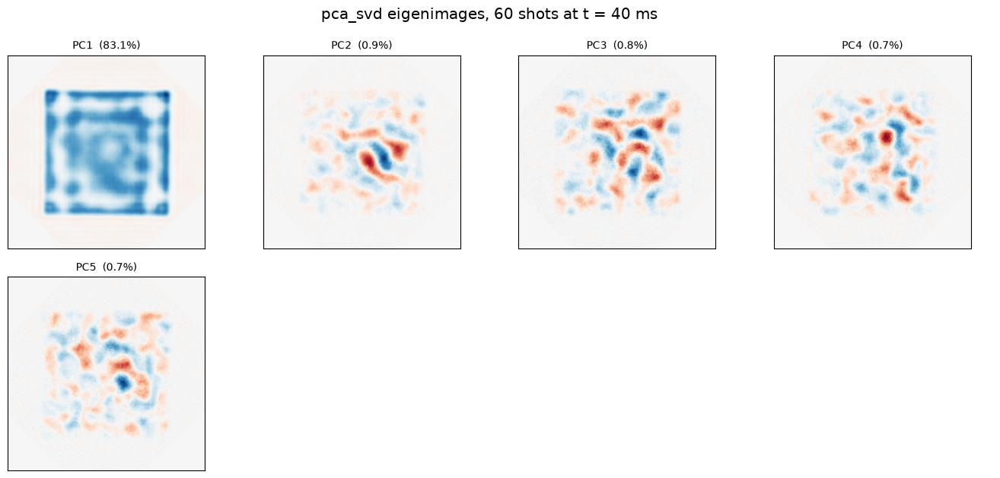

In [ ]:
# pca_svd on the full 60-shot t = 40 ms dataset (2026-07-27_40ms/):
# eigenvalue spectrum on log-lin axes, then the leading eigenimages.
PCA60_DIR = os.path.join(SCRIPT_DIR, "2026-07-27_40ms")
N_EIG_SHOW = 4   # leading eigenimages to display

stack60_svd = np.stack([
    rotate(ShotFile(p, cam=CAM, crop_box=CROP_BOX).od,45,reshape=False)
    for p in sorted(glob.glob(os.path.join(PCA60_DIR, "*bec_box2*.h5")))
])
print(f"image stack: {stack60_svd.shape}")

evals60_svd, evecs60_svd = pca_svd(stack60_svd)

# eigenvalue spectrum, log-lin
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.semilogy(np.arange(1, len(evals60_svd) + 1), evals60_svd, "o-", ms=4, color="C0")
ax.set_xlabel("component #")
ax.set_ylabel("eigenvalue (fraction of total)")
ax.set_title(f"pca_svd eigenvalues, {len(stack60_svd)} shots at t = 40 ms")
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()

# table of the leading eigenimages
ncols = 4
nrows = int(np.ceil(N_EIG_SHOW / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.2 * nrows))
for j, ax in enumerate(axes.ravel()):
    if j >= N_EIG_SHOW:
        ax.axis("off")
        continue
    comp = evecs60_svd[..., j]
    lim = np.abs(comp).max()
    ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC{j + 1}  ({evals60_svd[j]:.1%})", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"pca_svd eigenimages, {len(stack60_svd)} shots at t = 40 ms")
fig.tight_layout()
plt.show()


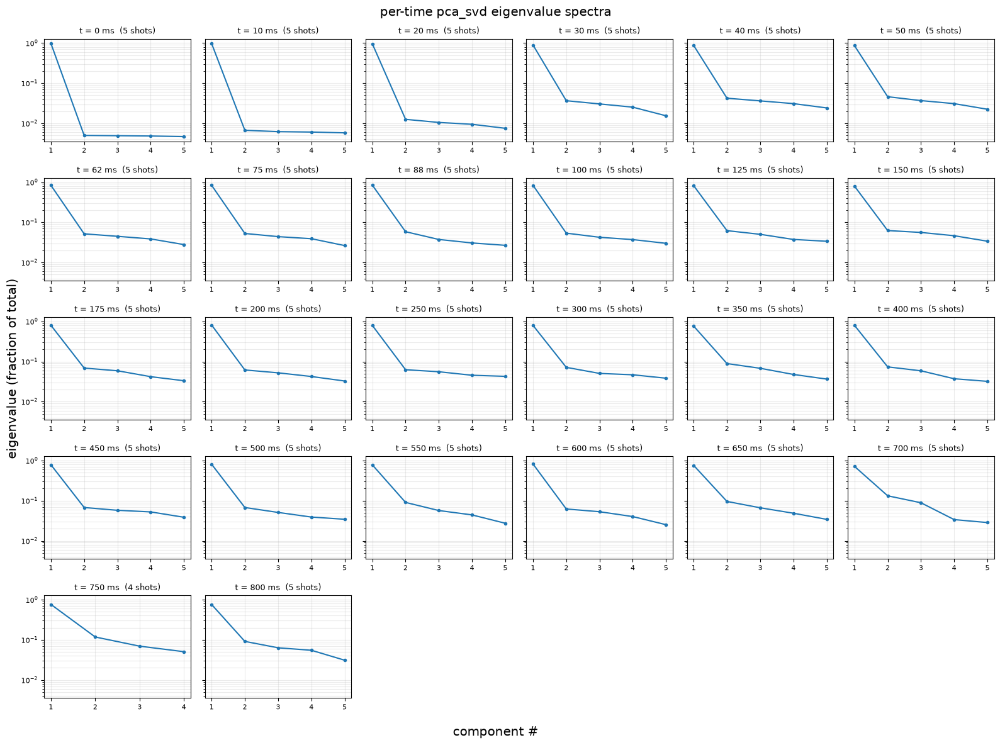

In [ ]:
# Per-time PCA over the evolution dataset (~5 shots per time): pca_svd on
# each time's shots ALONE, every eigenvalue spectrum on log-lin axes.
# n shots at a time -> n eigenvalues in that spectrum.
pca_by_time_svd = {_t: pca_svd(stack_svd[t_shots_svd == _t]) for _t in times_svd}

ncols = 6
nrows = int(np.ceil(len(times_svd) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.4 * nrows),
                         sharey=True)
for ax, _t in zip(axes.ravel(), times_svd):
    evals_t, _ = pca_by_time_svd[_t]
    ax.semilogy(np.arange(1, len(evals_t) + 1), evals_t, "o-", ms=3, color="C0")
    ax.set_title(f"t = {_t:g} ms  ({len(evals_t)} shots)", fontsize=9)
    ax.set_xticks(np.arange(1, len(evals_t) + 1))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.25, which="both")
for ax in axes.ravel()[len(times_svd):]:
    ax.axis("off")
fig.supxlabel("component #")
fig.supylabel("eigenvalue (fraction of total)")
fig.suptitle("log-lin pca_svd eigenvalues")
fig.tight_layout()
plt.show()


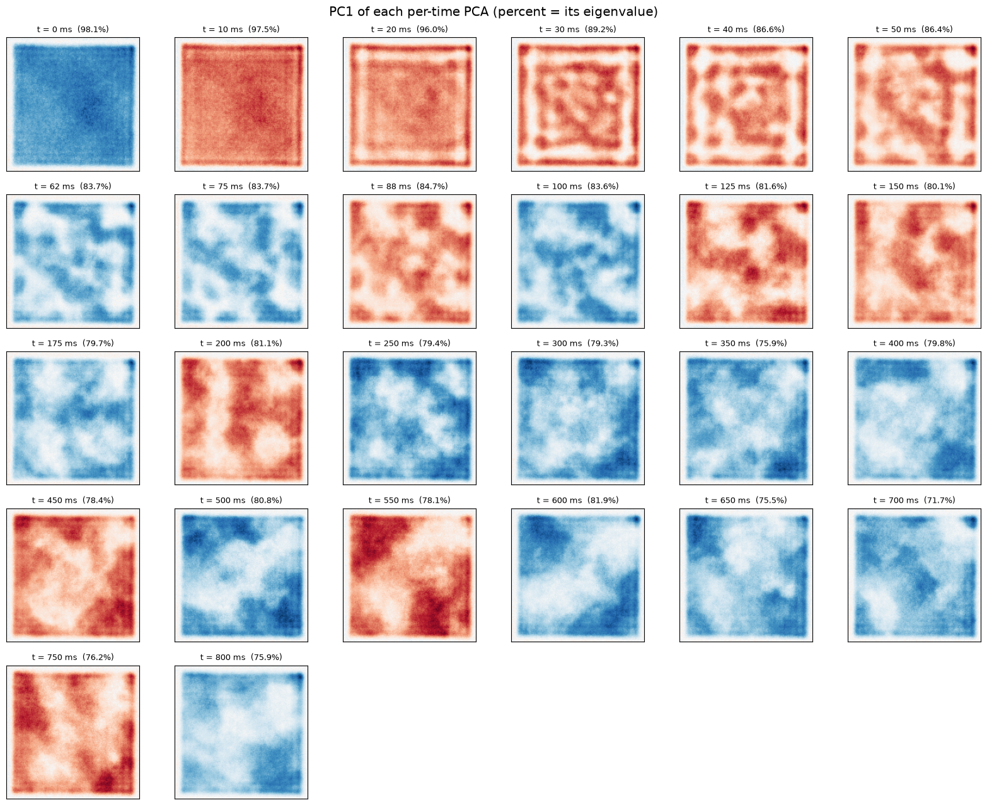

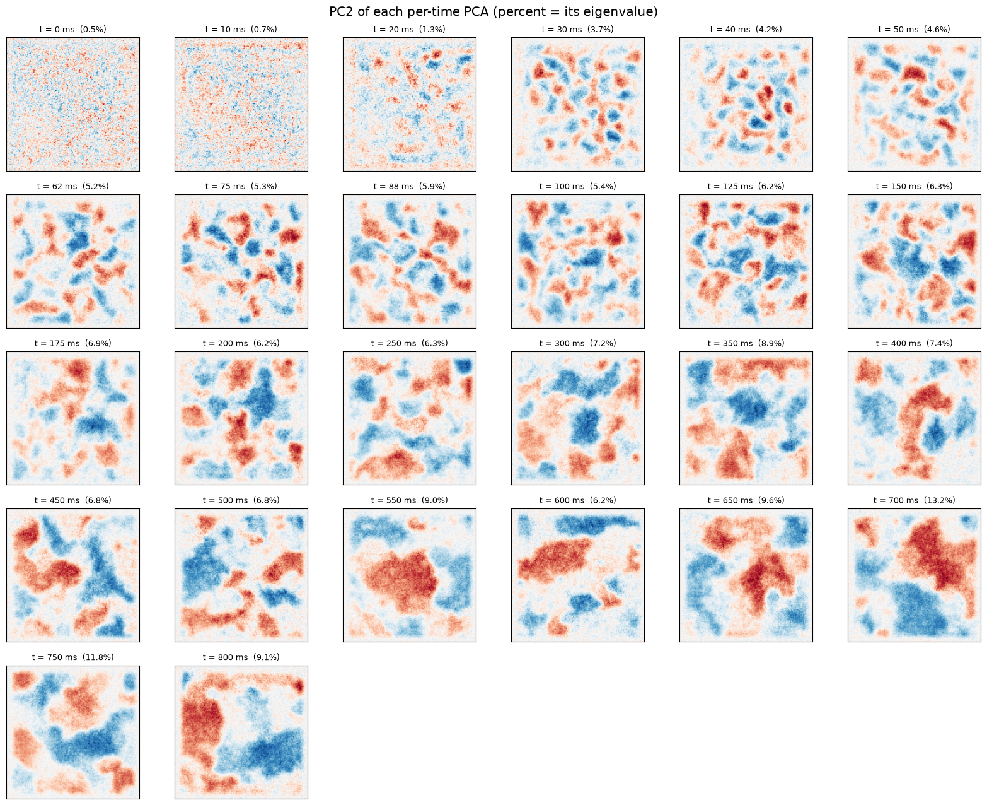

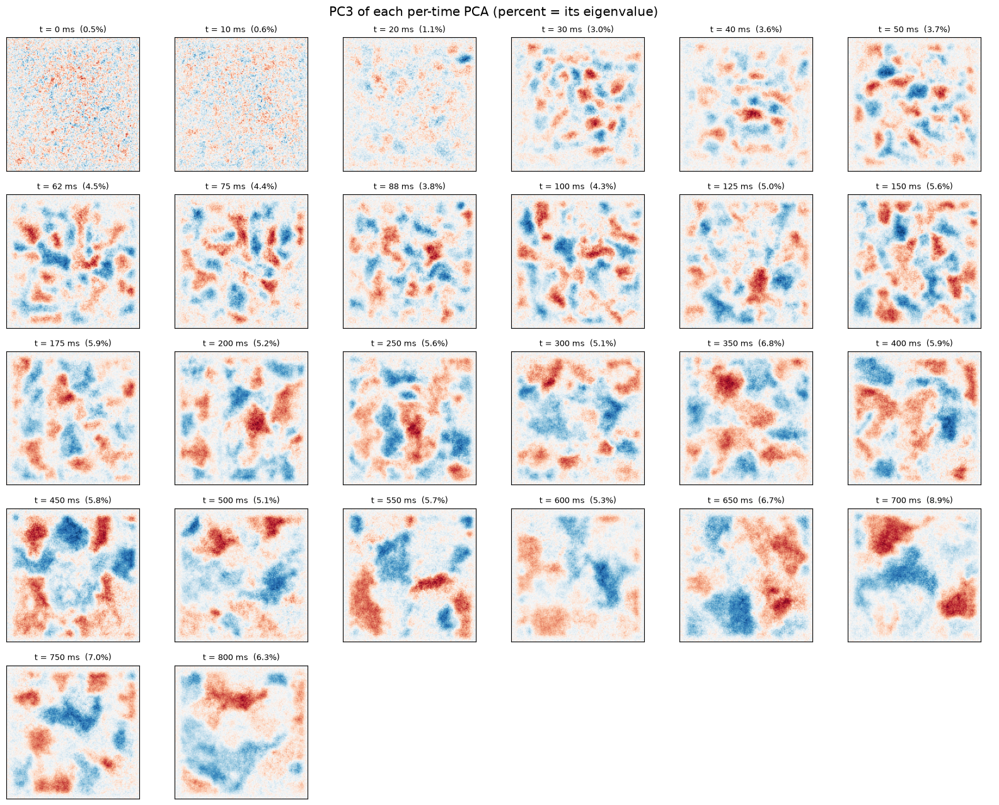

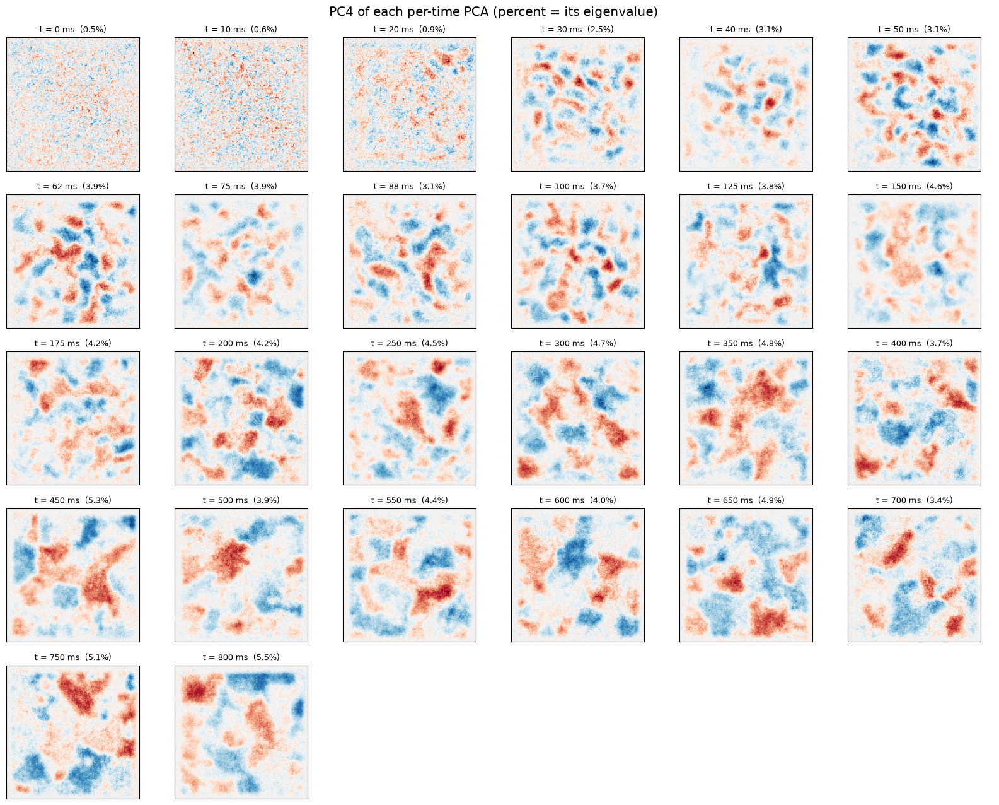

In [46]:
# The k-th eigenvector of each per-time PCA as an image: one table per
# component for PC1..PC4 (reuses pca_by_time_svd from the cell above).
ncols = 6
nrows = int(np.ceil(len(times_svd) / ncols))
for k in range(4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.6 * nrows))
    for ax, _t in zip(axes.ravel(), times_svd):
        evals_t, evecs_t = pca_by_time_svd[_t]
        ax.set_xticks([])
        ax.set_yticks([])
        if k >= evecs_t.shape[-1]:
            ax.axis("off")
            continue
        comp = evecs_t[..., k]
        lim = np.abs(comp).max()
        ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"t = {_t:g} ms  ({evals_t[k]:.1%})", fontsize=9)
    for ax in axes.ravel()[len(times_svd):]:
        ax.axis("off")
    fig.suptitle(f"PC{k + 1} of each per-time PCA (percent = its eigenvalue)")
    fig.tight_layout()
    plt.show()


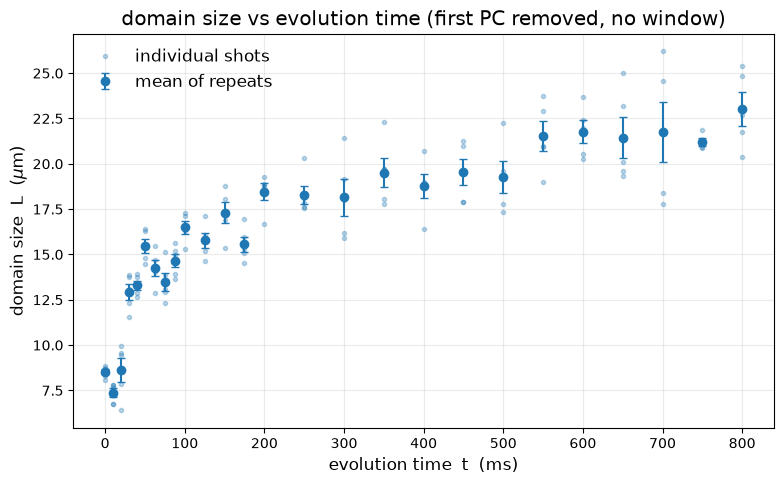

In [ ]:
# Variant 1: remove the FIRST principal component, NO window.
# L = 2 pi <S> / <k S> straight on the cleaned shot.
L_shots_svd1 = np.array([_domain_length_raw(remove_pca_components(im, pcs_svd, 1)[0])
                         for im in stack_svd]) * 0.66
_tm = np.array(times_svd, float)
L_mean_svd1 = np.array([L_shots_svd1[t_shots_svd == t].mean() for t in times_svd])
L_sem_svd1 = np.array([L_shots_svd1[t_shots_svd == t].std(ddof=1)
                       / np.sqrt((t_shots_svd == t).sum()) for t in times_svd])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots_svd, L_shots_svd1, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(_tm, L_mean_svd1, yerr=L_sem_svd1, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("domain size vs evolution time (first PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


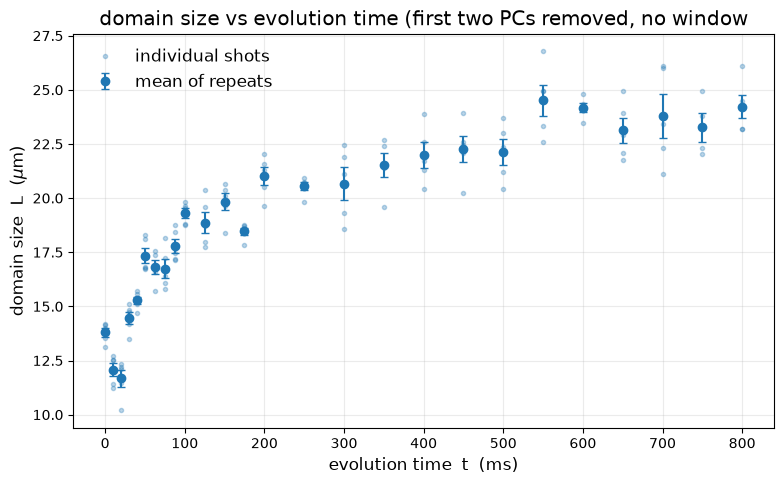

In [48]:
# Variant 2: remove the first TWO principal components, THEN mean-subtract
# and taper with a 2D tukey window before the same L estimator.
def _domain_length_svd2_windowed(im, alpha=WIN_ALPHA_SVD):
    cleaned, _ = remove_pca_components(im, pcs_svd, 2)
    win = np.outer(tukey(cleaned.shape[0], alpha), tukey(cleaned.shape[1], alpha))
    return _domain_length_raw((cleaned - cleaned.mean()) * win)


L_shots_svd2w = np.array([_domain_length_raw(im)
                          for im in stack_svd]) * PIXEL_UM_SVD
_tm = np.array(times_svd, float)
L_mean_svd2w = np.array([L_shots_svd2w[t_shots_svd == t].mean() for t in times_svd])
L_sem_svd2w = np.array([L_shots_svd2w[t_shots_svd == t].std(ddof=1)
                        / np.sqrt((t_shots_svd == t).sum()) for t in times_svd])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots_svd, L_shots_svd2w, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(_tm, L_mean_svd2w, yerr=L_sem_svd2w, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title(f"domain size vs evolution time "
             f"(first two PCs removed, no window")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
